In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hilbert

In [29]:
def rel_res(H, b, x):
    return np.linalg.norm(b - H @ x) / np.linalg.norm(b)

def rel_err(x, xstar):
    return np.linalg.norm(x - xstar) / np.linalg.norm(xstar)

def gauss_seidel(H, b, tol=1e-4, maxit=10000):
    n = len(b)
    x = np.zeros(n)
    hist = []
    for k in range(maxit + 1):
        r = b - H @ x
        rr = np.linalg.norm(r) / np.linalg.norm(b)
        ee = rel_err(x, np.ones(n))
        hist.append([k, rr, ee])
        if rr <= tol:
            break
        if k == maxit:
            break
        for i in range(n):
            s = b[i] - H[i, :i] @ x[:i] - H[i, i+1:] @ x[i+1:]
            x[i] = s / H[i, i]
    return x, np.array(hist)

def steepest_descent(H, b, tol=1e-4, maxit=10000):
    n = len(b)
    x = np.zeros(n)
    hist = []
    for k in range(maxit + 1):
        r = b - H @ x
        rr = np.linalg.norm(r) / np.linalg.norm(b)
        ee = rel_err(x, np.ones(n))
        hist.append([k, rr, ee])
        if rr <= tol:
            break
        if k == maxit:
            break
        Hr = H @ r
        alpha = (r @ r) / (r @ Hr)
        x = x + alpha * r
    return x, np.array(hist)

In [30]:
ns = np.arange(2, 14)
conds = []
direct_res, direct_err = [], []
gs_res, gs_err = [], []
sd_res, sd_err = [], []

for n in ns:
    H = hilbert(n)
    xstar = np.ones(n)
    b = H @ xstar

    conds.append(np.linalg.cond(H, 2))

    # direct solve
    try:
        xd = np.linalg.solve(H, b)
        direct_res.append(rel_res(H, b, xd))
        direct_err.append(rel_err(xd, xstar))
    except np.linalg.LinAlgError:
        direct_res.append(np.nan)
        direct_err.append(np.nan)
        print(f"Direct solve failed for n={n}: numerically singular")

    # Gauss-Seidel
    xg, _ = gauss_seidel(H, b)
    gs_res.append(rel_res(H, b, xg))
    gs_err.append(rel_err(xg, xstar))

    # steepest descent
    xs, _ = steepest_descent(H, b)
    sd_res.append(rel_res(H, b, xs))
    sd_err.append(rel_err(xs, xstar))

# (a)

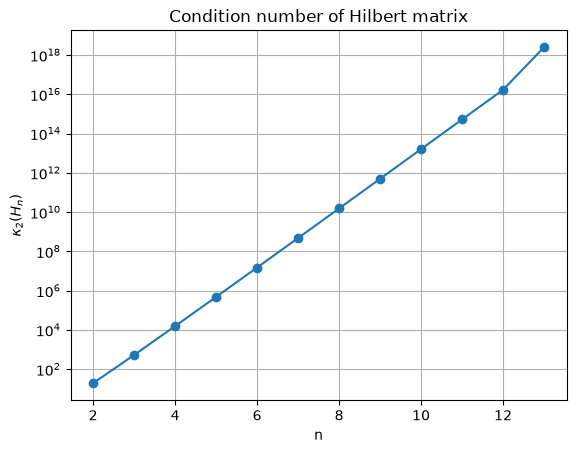

In [31]:
plt.figure()
plt.semilogy(ns, conds, 'o-')
plt.xlabel('n')
plt.ylabel(r'$\kappa_2(H_n)$')
plt.title('Condition number of Hilbert matrix')
plt.grid(True, which='both')
plt.show()

# (b)

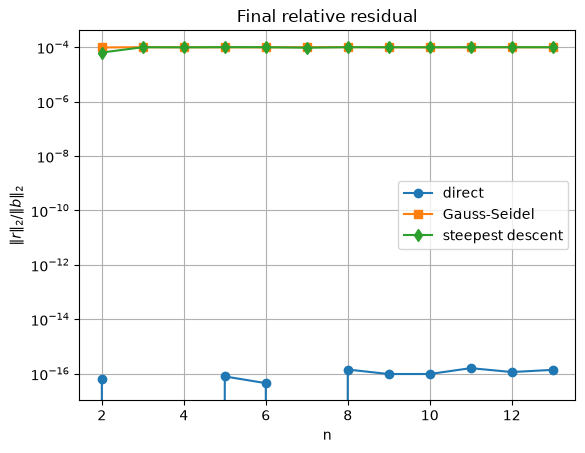

In [32]:
plt.figure()
plt.semilogy(ns, direct_res, 'o-', label='direct')
plt.semilogy(ns, gs_res, 's-', label='Gauss-Seidel')
plt.semilogy(ns, sd_res, 'd-', label='steepest descent')
plt.xlabel('n')
plt.ylabel(r'$\|r\|_2/\|b\|_2$')
plt.title('Final relative residual')
plt.legend()
plt.grid(True, which='both')
plt.show()

# (c)

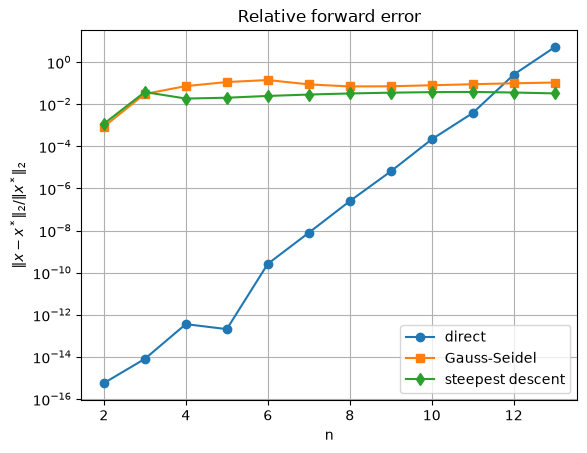

In [33]:
plt.figure()
plt.semilogy(ns, direct_err, 'o-', label='direct')
plt.semilogy(ns, gs_err, 's-', label='Gauss-Seidel')
plt.semilogy(ns, sd_err, 'd-', label='steepest descent')
plt.xlabel('n')
plt.ylabel(r'$\|x-x^*\|_2/\|x^*\|_2$')
plt.title('Relative forward error')
plt.legend()
plt.grid(True, which='both')
plt.show()

#### As \(n\) increases, the forward error for the direct solve grows largely. Gauss–Seidel and steepest descent stop with relative residual \(10^{-4}\), but the forward error is much larger. A small residual does **not** necessarily imply a small forward error.

# (d)
#### The Hilbert matrix is ill-conditioned; $\kappa_2(H_n)$ becomes enormous. For the direct solve, the relative residual is be about $10^{-16}$, but the bound gives $\text{relative error} \lesssim \kappa_2(H_n) \cdot 10^{-16}$. If $\kappa_2(H_n) > 10^{16}$, the bound exceeds $1$, so a small residual gives no useful indicator of accuracy.

# (e)

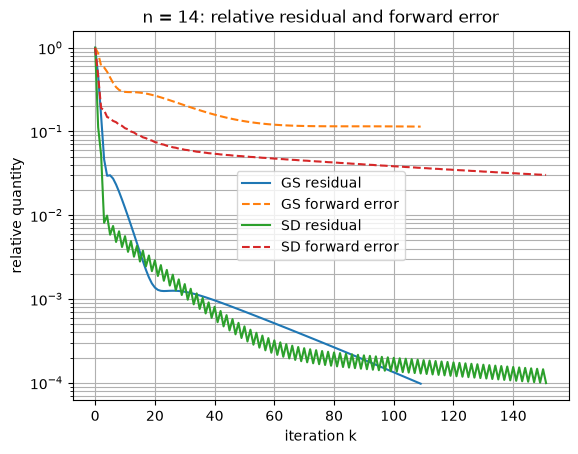

n=14
Gauss-Seidel final: k = 109.0  relres = 9.750813751394782e-05  relerr = 0.11426892117942912
Steepest descent final: k = 151.0  relres = 9.910221754105073e-05  relerr = 0.030252497056589903


In [34]:

n = 14
H = hilbert(n)
xstar = np.ones(n)
b = H @ xstar

xg, hg = gauss_seidel(H, b, tol=1e-4, maxit=10000)
xs, hs = steepest_descent(H, b, tol=1e-4, maxit=10000)

plt.figure()
plt.semilogy(hg[:, 0], hg[:, 1], label='GS residual')
plt.semilogy(hg[:, 0], hg[:, 2], '--', label='GS forward error')
plt.semilogy(hs[:, 0], hs[:, 1], label='SD residual')
plt.semilogy(hs[:, 0], hs[:, 2], '--', label='SD forward error')
plt.xlabel('iteration k')
plt.ylabel('relative quantity')
plt.title('n = 14: relative residual and forward error')
plt.legend()
plt.grid(True, which='both')
plt.show()

print("n=14")
print("Gauss-Seidel final: k =", hg[-1,0],
      " relres =", hg[-1,1],
      " relerr =", hg[-1,2])
print("Steepest descent final: k =", hs[-1,0],
      " relres =", hs[-1,1],
      " relerr =", hs[-1,2])

#### The residual curves decrease slowly but stay above $10^{-4}$. The forward-error curves decrease only slightly and then stagnate. This shows that the residual and forward error are not proportional. The residual can improve by orders of magnitude while the forward error remains large.